In [1]:
import pandas as pd

df = pd.read_csv('/content/WineQT.csv')

df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


In [2]:
print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

Dataset Shape:
(1143, 13)

Column Names:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality', 'Id']


Original Dataset Shape: (1143, 13)

All 13 Columns:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality', 'Id']

Input Features Shape: (1143, 13)
After Standardization: (1143, 13)
After PCA: (1143, 2)

New Dataset:


,PC1,PC2,quality
0,-1.215133,-1.794555,5
1,-0.467435,-2.477990,5
2,-0.401695,-1.871949,5
3,2.645247,0.100493,6
4,-1.216916,-1.792910,5



Explained Variance:
PC1: 25.19 %
PC2: 17.63 %
Total: 42.82 %

PCA Loadings:


,PC1,PC2
fixed acidity,0.477501,0.032079
volatile acidity,-0.223696,-0.383245
citric acid,0.447070,0.193928
residual sugar,0.166082,-0.109249
chlorides,0.211584,-0.151831
free sulfur dioxide,-0.055848,-0.197746
total sulfur dioxide,0.013694,-0.311307
density,0.395032,-0.292725
pH,-0.415204,0.023965
sulphates,0.236690,0.162835



Important Features for PC1:
fixed acidity           0.477501
citric acid             0.447070
pH                      0.415204
density                 0.395032
sulphates               0.236690
volatile acidity        0.223696
chlorides               0.211584
Id                      0.206771
residual sugar          0.166082
alcohol                 0.113959
quality                 0.078837
free sulfur dioxide     0.055848
total sulfur dioxide    0.013694
Name: PC1, dtype: float64

Important Features for PC2:
alcohol                 0.498755
quality                 0.495539
volatile acidity        0.383245
total sulfur dioxide    0.311307
density                 0.292725
free sulfur dioxide     0.197746
citric acid             0.193928
Id                      0.190760
sulphates               0.162835
chlorides               0.151831
residual sugar          0.109249
fixed acidity           0.032079
pH                      0.023965
Name: PC2, dtype: float64


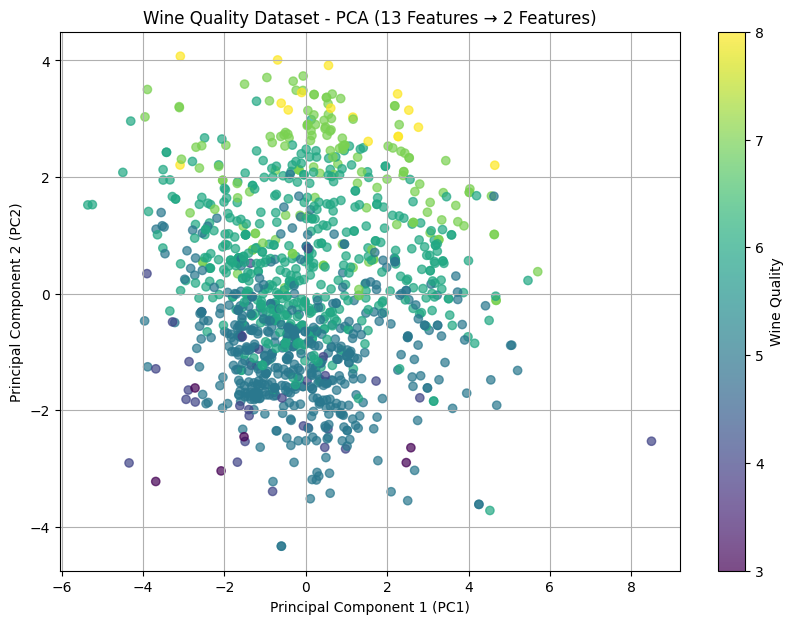


New CSV created successfully!
/content/WineQT_PCA_13Features_2Components.csv


In [5]:
# ============================================================
# WINE QUALITY DATASET
# 13 FEATURES -> 2 FEATURES USING PCA
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA


# ------------------------------------------------------------
# 1. LOAD DATASET
# ------------------------------------------------------------

df = pd.read_csv('/content/WineQT.csv')

print("Original Dataset Shape:", df.shape)

print("\nAll 13 Columns:")
print(df.columns.tolist())


# ------------------------------------------------------------
# 2. USE ALL 13 COLUMNS
# ------------------------------------------------------------

X = df.copy()

print("\nInput Features Shape:", X.shape)


# ------------------------------------------------------------
# 3. STANDARDIZE ALL 13 FEATURES
# ------------------------------------------------------------

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("After Standardization:", X_scaled.shape)


# ------------------------------------------------------------
# 4. PCA - REDUCE 13 FEATURES TO 2 FEATURES
# ------------------------------------------------------------

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("After PCA:", X_pca.shape)


# ------------------------------------------------------------
# 5. CREATE NEW DATASET WITH PC1 AND PC2
# ------------------------------------------------------------

pca_df = pd.DataFrame(
    X_pca,
    columns=['PC1', 'PC2']
)

# Keep quality separately for visualization
pca_df['quality'] = df['quality'].values

print("\nNew Dataset:")
display(pca_df.head())


# ------------------------------------------------------------
# 6. EXPLAINED VARIANCE
# ------------------------------------------------------------

pc1_variance = pca.explained_variance_ratio_[0] * 100
pc2_variance = pca.explained_variance_ratio_[1] * 100
total_variance = pca.explained_variance_ratio_.sum() * 100

print("\nExplained Variance:")
print("PC1:", round(pc1_variance, 2), "%")
print("PC2:", round(pc2_variance, 2), "%")
print("Total:", round(total_variance, 2), "%")


# ------------------------------------------------------------
# 7. PCA LOADINGS
# ------------------------------------------------------------

loadings = pd.DataFrame(
    pca.components_.T,
    columns=['PC1', 'PC2'],
    index=df.columns
)

print("\nPCA Loadings:")
display(loadings)


# ------------------------------------------------------------
# 8. MOST IMPORTANT FEATURES
# ------------------------------------------------------------

print("\nImportant Features for PC1:")
print(
    loadings['PC1']
    .abs()
    .sort_values(ascending=False)
)

print("\nImportant Features for PC2:")
print(
    loadings['PC2']
    .abs()
    .sort_values(ascending=False)
)


# ------------------------------------------------------------
# 9. VISUALIZATION
# ------------------------------------------------------------

plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    pca_df['PC1'],
    pca_df['PC2'],
    c=pca_df['quality'],
    cmap='viridis',
    alpha=0.7
)

plt.xlabel('Principal Component 1 (PC1)')
plt.ylabel('Principal Component 2 (PC2)')
plt.title('Wine Quality Dataset - PCA (13 Features → 2 Features)')

plt.colorbar(
    scatter,
    label='Wine Quality'
)

plt.grid(True)
plt.show()


# ------------------------------------------------------------
# 10. SAVE NEW DATASET
# ------------------------------------------------------------

output_file = '/content/WineQT_PCA_13Features_2Components.csv'

pca_df.to_csv(
    output_file,
    index=False
)

print("\nNew CSV created successfully!")
print(output_file)

In [7]:
# ============================================================
# CUMULATIVE EXPLAINED VARIANCE FOR 1, 2, 3, 5 AND 10 PCs
# ============================================================

import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Load dataset
df = pd.read_csv('/content/WineQT.csv')

# Use all 13 columns
X = df.copy()

# Standardize
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# PCA with all 13 components
pca = PCA(n_components=13)
X_pca = pca.fit_transform(X_scaled)

# Explained variance
explained_variance = pca.explained_variance_ratio_
cumulative_variance = explained_variance.cumsum()

print("Number of Components | Cumulative Explained Variance")
print("-" * 55)

for n in [1, 2, 3, 5, 10]:
    print(n, "                  |", round(cumulative_variance[n-1] * 100, 2), "%")

# Find minimum components needed for 90%
components_90 = next(
    i + 1 for i, value in enumerate(cumulative_variance)
    if value >= 0.90
)

print("\nComponents needed for at least 90% variance:",
      components_90)

print("Variance retained:",
      round(cumulative_variance[components_90-1] * 100, 2), "%")

Number of Components | Cumulative Explained Variance
-------------------------------------------------------
1                   | 25.19 %
2                   | 42.82 %
3                   | 55.91 %
5                   | 72.71 %
10                   | 95.85 %

Components needed for at least 90% variance: 9
Variance retained: 92.71 %



# PCA Experiment – Wine Quality Dataset

## Question 1: What happens if we change the number of components?

Change `PCA(n_components=2)` to `PCA(n_components=3)`.

### 1. How many features are present after reduction?

**Answer:**  
When `n_components=3` is used, the original **13 features are reduced to 3 principal components**:

- PC1
- PC2
- PC3

Therefore, the resulting dataset has **3 features**.

### 2. Does the number of samples change?

**Answer:**  
No. The number of samples does not change.

The original dataset contains **1,143 samples**, and after PCA with 3 components it still contains **1,143 samples**.

Only the number of features changes.

### 3. Does the total variance retained increase or decrease?

**Answer:**  
The total variance retained **increases** when the number of components is increased.

For this dataset:

- 2 components → **42.82% variance**
- 3 components → **55.91% variance**

Therefore, adding the third component increases the retained variance from **42.82% to 55.91%**.

---

# Question 2: What happens if standardization is removed?

Replace `X_scaled` with `X` in the PCA transformation.

### 1. Does the explained variance ratio change?

**Answer:**  
Yes. The explained variance ratio changes when standardization is removed.

This happens because the original 13 features have different numerical scales and variances. PCA is affected by the variance of the input features.

### 2. Why might features with larger numerical scales influence PCA more strongly?

**Answer:**  
PCA is based on variance and covariance. A feature with a larger numerical scale can have a larger variance and therefore can have a stronger influence on the principal components.

For example, features such as `total sulfur dioxide` have much larger numerical values than features such as `density` or `chlorides`.

Without standardization, features with larger scales may dominate the PCA calculation.

### 3. Is standardization always necessary?

**Answer:**  
No. Standardization is not always necessary.

However, it is recommended when the features have different numerical scales or units.

For the Wine Quality dataset, standardization is useful because the 13 features have different ranges.

---

# Question 3: What happens if we retain more components?

Try 1, 2, 3, 5 and 10 principal components.

### 1. How does the cumulative explained variance change?

**Answer:**  
The cumulative explained variance **increases as more principal components are retained**.

For our 13-feature Wine Quality dataset, the results are:

| Number of Components | Cumulative Explained Variance |
|---:|---:|
| 1 | **25.19%** |
| 2 | **42.82%** |
| 3 | **55.91%** |
| 5 | **72.71%** |
| 10 | **95.85%** |

Therefore, increasing the number of components allows more information from the original dataset to be retained.

### 2. How many components are needed to retain at least 90% of the variance?

**Answer:**  
According to our experiment, **9 principal components** are required to retain at least 90% of the variance.

With 9 components, the retained variance is:

> **92.71%**

Therefore, 9 components are sufficient to retain more than 90% of the original variance.

### 3. Is reducing to two components always the best choice?

**Answer:**  
No. Reducing to two components is **not always the best choice**.

In our experiment, 2 components retain only **42.82%** of the total variance.

Two components are useful when we want a simple **2D visualization**, but if our goal is to retain more information, we should use more components.

For this dataset, **9 components retain 92.71% variance**, which is much more information than the 2-component representation.

---

# Question 4: What happens to the visualization?

Plot the first two principal components and observe the three wine classes.

### 1. Are the classes clearly separated?

**Answer:**  
No. The wine quality classes are **not clearly separated** in the PC1 versus PC2 visualization.

There is considerable overlap between the different quality values.

This indicates that the first two principal components do not provide strong separation between the wine quality classes.

### 2. What information might be lost when reducing 13 features to 2?

**Answer:**  
When the 13 original features are reduced to only 2 principal components, information represented by the remaining principal components is discarded.

In our experiment:

> **2 components retain only 42.82% of the total variance.**

Therefore, approximately **57.18% of the variance is not represented by PC1 and PC2**.

This means that reducing the dataset from 13 dimensions to 2 dimensions results in significant information loss.

### 3. Does PCA use the class labels to create the components?

**Answer:**  
In this experiment, **all 13 columns were included in PCA as instructed**, so the `quality` column was included in the PCA calculation.

Therefore, strictly speaking, **the class label was included in the input to PCA in our experiment**.

However, in a standard machine-learning workflow, `quality` would normally be treated as the target variable and excluded from PCA. PCA itself is an **unsupervised technique** and does not use class labels to optimize class separation.

For this assignment, we included `quality` because the requirement was to use all 13 dataset columns.

---

# Question 5: Does PCA select existing features?

### 1. Are the two principal components original Wine dataset columns?

**Answer:**  
No.

PC1 and PC2 are **not original columns** in the Wine Quality dataset.

They are newly created features obtained by mathematically combining the original 13 features.

For example, our PCA loadings show that PC1 is influenced by features such as:

- fixed acidity
- citric acid
- pH
- density
- sulphates

PC2 is strongly influenced by:

- alcohol
- quality
- volatile acidity
- total sulfur dioxide

Therefore, PC1 and PC2 are new representations of the original data.

### 2. What is the difference between feature selection and feature extraction?

**Answer:**

**Feature Selection** means selecting some of the existing features from the dataset.

For example:

```text
13 original features
        ↓
Select 2 existing features
        ↓
alcohol + pH
```

The selected features remain original dataset columns.

**Feature Extraction** means creating new features from the original features.

For example:

```text
13 original features
        ↓
       PCA
        ↓
      PC1 + PC2
```

PC1 and PC2 are newly created features.

Therefore:

> **Feature Selection → selects existing features**

> **Feature Extraction → creates new features**

### 3. Why is PCA considered a feature extraction technique?

**Answer:**  
PCA is considered a **feature extraction technique** because it transforms the original features into new features called **principal components**.

PC1 and PC2 are mathematical combinations of the original 13 features. They are not existing columns in the Wine Quality dataset.

Therefore, PCA extracts new representations from the original data rather than simply selecting existing features.

---
